# Assignment 5 - Random Forest Classifier

Predict car safety using a Random Forest classifier.

*Dataset: Car Evaluation dataset.*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42

## 1. Load and prepare the data

In [2]:
columns = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]
df = pd.read_csv("car.data", names=columns)

X = df.drop(columns=["class"])
y = df["class"]

print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Classes:", y.value_counts().to_dict())

Dataset shape: (1728, 7)
Missing values: 0
Classes: {'unacc': 1210, 'acc': 384, 'good': 69, 'vgood': 65}


## 2. Split the data

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

categorical_features = X.columns.tolist()
preprocessor = ColumnTransformer(
    [("onehot", OneHotEncoder(handle_unknown="ignore"), categorical_features)]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced"
    )),
])

## 3. Train the Random Forest model

In [4]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 96.92%

Classification Report:

              precision    recall  f1-score   support

         acc       0.89      0.98      0.93       115
        good       0.95      1.00      0.98        21
       unacc       1.00      0.96      0.98       363
       vgood       0.95      1.00      0.98        20

    accuracy                           0.97       519
   macro avg       0.95      0.99      0.97       519
weighted avg       0.97      0.97      0.97       519



## 4. Evaluate the model

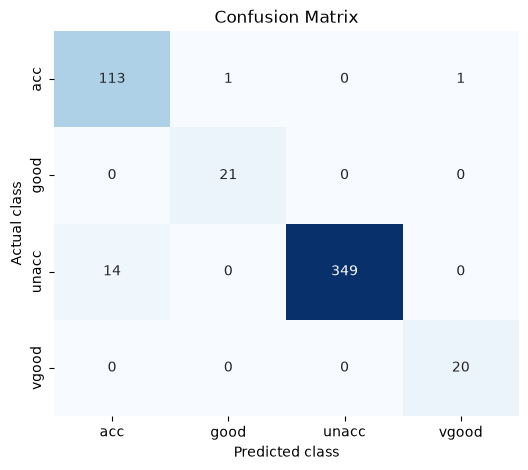

In [5]:
labels = model.named_steps["classifier"].classes_
confusion = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion Matrix")
plt.show()

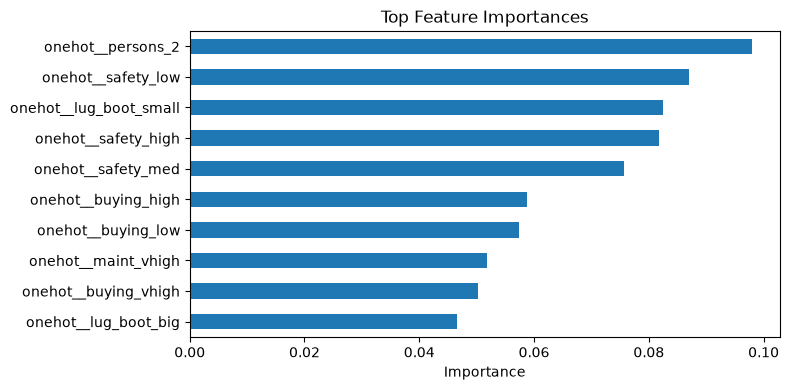

In [6]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importance = model.named_steps["classifier"].feature_importances_
top_features = (
    pd.Series(importance, index=feature_names)
    .sort_values(ascending=False)
    .head(10)
)

top_features.sort_values().plot(kind="barh", figsize=(8, 4))
plt.xlabel("Importance")
plt.title("Top Feature Importances")
plt.tight_layout()
plt.show()

## Conclusion

The Random Forest model classifies car-evaluation categories from the six categorical features. One-hot encoding converts the categories into numeric features before training.